# EgyptOra | Destination segmentation & similarity
**DigiLiAns Data Analysis Capstone · September 2026**  
**Machine Learning & Advanced Analytics — Abdelrahman Omar**

Reproducible portfolio edition of the team's unsupervised learning workflow. The objective is to segment Egyptian tourism destinations by their attraction supply, accessibility and climate, and recommend structurally similar destinations. It is **not a visitor-demand forecast**.

**Run:** Place `EgyptOra_ML_Ready.xlsx` alongside this notebook in `machine-learning/`. Install the packages below, then use **Restart Kernel and Run All**. The original workbook is read-only; optional CSV exports are off by default. The existing capstone workbook provides feature-engineered inputs and reference outputs for verification, not supervised training targets.

Tested with Python 3.11+ compatible packages (exact tested versions printed below). Install in your notebook environment: `pip install pandas numpy openpyxl scikit-learn scipy matplotlib`.

### Workflow
Input audit → eligible features → StandardScaler → PCA (90% variance target) → K-Means (K=2–6) → cluster interpretation → top-three similarity → reconciliation with published outputs.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
import scipy
import openpyxl
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.metrics.pairwise import pairwise_distances
from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}")
print(f"scikit-learn {sklearn.__version__} | SciPy {scipy.__version__} | openpyxl {openpyxl.__version__} | matplotlib {matplotlib.__version__}")
SEED = 42
N_INIT = 100
SELECTED_K = 4
EXPORT_CSV = False

Python 3.13.5 | pandas 2.2.3 | NumPy 2.3.5
scikit-learn 1.8.0 | SciPy 1.17.0 | openpyxl 3.1.5 | matplotlib 3.10.8


## 1. Load the actual capstone dataset
The previous notebook referenced `Destination_Features.xlsx`, which is not the supplied workbook. Use `ML_Destinations` in `EgyptOra_ML_Ready.xlsx`. The existing cluster outputs are retained separately for reconciliation only.

In [2]:
candidates = [Path("EgyptOra_ML_Ready.xlsx"), Path("machine-learning/EgyptOra_ML_Ready.xlsx"),
              Path("EgyptOra_ML_Ready(1).xlsx")]
path = next((p for p in candidates if p.is_file()), None)
if path is None:
    raise FileNotFoundError("Place EgyptOra_ML_Ready.xlsx beside the notebook or in machine-learning/.")
with pd.ExcelFile(path) as workbook:
    source = pd.read_excel(workbook, sheet_name="ML_Destinations")
    reference_eval = pd.read_excel(workbook, sheet_name="ML_Model_Evaluation")
    reference_profiles = pd.read_excel(workbook, sheet_name="ML_Cluster_Profiles")
    reference_similar = pd.read_excel(workbook, sheet_name="ML_Similar")
    feature_guide = pd.read_excel(workbook, sheet_name="ML_Feature_Guide")
print(f"Loaded {path.name}: {source.shape[0]} destinations, {source.shape[1]} columns")
display(source[["destination_id", "destination", "ml_status"]].head())

Loaded EgyptOra_ML_Ready.xlsx: 38 destinations, 24 columns


,destination_id,destination,ml_status
0,DST_01,Cairo,Included in ML
1,DST_02,Giza,Included in ML
2,DST_03,Saqqara and Dahshur,Included in ML
3,DST_04,Alexandria,Included in ML
4,DST_05,North Coast,Included in ML


## 2. Eligibility and feature audit
Use the five features documented in `ML_Feature_Guide`. Six destinations have no linked attraction records, so their attraction/accessibility features cannot be computed without imputation. Preserve the exclusions and do not substitute zeros for missing values. The model consumes prepared features rather than reconstructing them from raw sources.

In [3]:
features = ["linked_attractions", "category_diversity", "avg_airport_distance_km",
            "avg_attraction_distance_km", "annual_avg_temp_c"]
required = ["destination_id", "destination", "ml_status", "exclusion_reason"] + features
missing = set(required) - set(source.columns)
assert not missing, f"Missing columns: {missing}"
assert source.destination_id.notna().all() and source.destination_id.is_unique
assert source.destination.notna().all() and source.destination.is_unique
eligible = source.ml_status.eq("Included in ML")
df = source.loc[eligible, ["destination_id", "destination", "governorate", "destination_type"] + features].reset_index(drop=True)
excluded = source.loc[~eligible, ["destination_id", "destination", "exclusion_reason"]].copy()
X = df[features].apply(pd.to_numeric, errors="coerce")
assert np.isfinite(X.to_numpy()).all(), "Eligible features contain missing/non-finite values. Review eligibility."
assert (X.drop(columns="annual_avg_temp_c") >= 0).all().all()
assert (X.std() > 0).all(), "Constant input feature detected."
print(f"Eligible: {len(df)} / {len(source)} | Excluded: {len(excluded)}")
display(excluded[["destination", "exclusion_reason"]])
display(feature_guide[feature_guide.Feature.isin(features)])
display(X.describe().round(2))

Eligible: 32 / 38 | Excluded: 6


,destination,exclusion_reason
6,Siwa Oasis,No records in Attraction Linked; attraction/ac...
8,Wadi El Hitan,No records in Attraction Linked; attraction/ac...
9,Bahariya Oasis,No records in Attraction Linked; attraction/ac...
10,Farafra and White Desert,No records in Attraction Linked; attraction/ac...
35,Damietta and Ras El Bar,No records in Attraction Linked; attraction/ac...
37,Wadi El Natrun,No records in Attraction Linked; attraction/ac...


,Feature,Used in K-Means,Definition,Source,Preprocessing / Notes
0,linked_attractions,Yes,Count of records linked to each destination.,Attraction Linked,Standardized (z-score). Missing linkage leads ...
1,category_diversity,Yes,Number of distinct attraction categories linke...,Attraction Linked,Standardized (z-score).
2,avg_attraction_distance_km,Yes,Mean straight-line distance from linked attrac...,Attraction Linked,Standardized. Distance is not road travel time.
3,avg_airport_distance_km,Yes,Mean nearest-airport distance across linked at...,Attraction Linked,Standardized. Descriptive accessibility proxy.
4,annual_avg_temp_c,Yes,Mean NASA T2M across all available monthly obs...,NASA Climate,Standardized. NASA POWER is modeled gridded cl...


,linked_attractions,category_diversity,avg_airport_distance_km,avg_attraction_distance_km,annual_avg_temp_c
count,32.00,32.00,32.00,32.00,32.00
mean,15.75,3.56,39.04,12.41,23.70
std,28.45,3.19,27.94,12.22,2.06
min,1.00,1.00,4.50,0.06,19.94
25%,2.00,1.00,16.08,4.79,21.90
50%,4.50,2.00,35.97,7.17,23.63
75%,12.00,5.00,52.61,20.00,25.39
max,141.00,12.00,113.60,45.16,26.77


## 3. Standardization and PCA
StandardScaler removes differences in units and scale. PCA retains at least 90% of total standardized feature variance for clustering. The first two components are shown in visualizations, but the model uses every retained component.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.90, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
print(f"Retained components: {pca.n_components_} | Explained variance: {pca.explained_variance_ratio_.sum():.2%}")
display(pd.DataFrame({"component": np.arange(1, pca.n_components_ + 1),
                      "explained_variance": pca.explained_variance_ratio_,
                      "cumulative_variance": pca.explained_variance_ratio_.cumsum()}).round(4))

Retained components: 4 | Explained variance: 92.25%


,component,explained_variance,cumulative_variance
0,1,0.4209,0.4209
1,2,0.2568,0.6777
2,3,0.1475,0.8251
3,4,0.0974,0.9225


## 4. Compare candidate K values
Silhouette: higher is better. Davies–Bouldin: lower is better. Cluster size and interpretability also matter. The original notebook used 50 initializations; this revision uses **100** to reproduce the supplied workbook's complete evaluation table in the tested environment. The capstone's K=4 choice remains unchanged.

,K,Silhouette_Score,Davies_Bouldin,Cluster_Sizes,Inertia,Selected_Model
0,2,0.3553,0.9945,"7, 25",96.4065,No
1,3,0.3829,0.9515,"6, 8, 18",62.2882,No
2,4,0.3576,0.9191,"6, 6, 8, 12",45.2396,Yes
3,5,0.3342,0.9623,"4, 6, 6, 8, 8",38.1865,No
4,6,0.3448,0.8764,"2, 4, 4, 5, 8, 9",31.6365,No


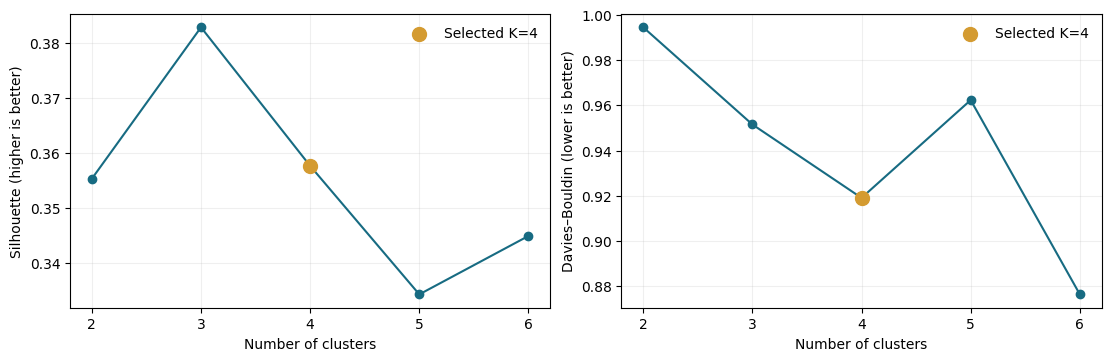

In [5]:
models, records = {}, []
with threadpool_limits(limits=1):
    for k in range(2, 7):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT)
        labels = model.fit_predict(X_pca)
        models[k] = model
        records.append({"K": k, "Silhouette_Score": silhouette_score(X_pca, labels),
                        "Davies_Bouldin": davies_bouldin_score(X_pca, labels),
                        "Cluster_Sizes": ", ".join(map(str, sorted(np.bincount(labels)))),
                        "Inertia": model.inertia_, "Selected_Model": "Yes" if k == SELECTED_K else "No"})
evaluation = pd.DataFrame(records)
display(evaluation.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, metric, label in zip(axes, ["Silhouette_Score", "Davies_Bouldin"], ["Silhouette (higher is better)", "Davies–Bouldin (lower is better)"]):
    ax.plot(evaluation.K, evaluation[metric], marker="o", color="#176b82")
    ax.scatter(SELECTED_K, evaluation.loc[evaluation.K.eq(SELECTED_K), metric], color="#d49b31", s=100, zorder=3, label="Selected K=4")
    ax.set(xlabel="Number of clusters", ylabel=label, xticks=evaluation.K)
    ax.grid(alpha=.2); ax.legend(frameon=False)
plt.show()

## 5. Final segmentation and stable business labels
K=3 has the highest Silhouette score; K=4 is the documented business choice because it improves Davies–Bouldin versus K=3, separates a remote/access-constrained group, and yields more actionable cluster sizes. K=6 has a lower Davies–Bouldin score but includes a very small segment.

K-Means numeric labels are arbitrary. Map fitted labels to the original workbook's business IDs by maximum overlap, **after fitting**. This is only a naming/reconciliation step, not a training target. If memberships differ, stop rather than silently reuse old business descriptions.

Membership agreement (Adjusted Rand Index): 1.000000


,cluster_id,cluster_name,destinations,linked_attractions,category_diversity,avg_airport_distance_km,avg_attraction_distance_km,annual_avg_temp_c,recommendation
0,1,Established High-Density Hubs,6,63.00,9.00,22.30,4.22,22.94,"Prioritize multi-attraction itineraries, cross..."
1,2,Compact Warm & Accessible,12,7.50,2.83,24.03,6.32,24.53,Build bundled itineraries and seasonal package...
2,3,Dispersed Moderate-Access,8,3.38,2.12,45.11,30.78,21.72,"Focus on route planning, ground-transport coor..."
3,4,Remote Low-Density / Access-Constrained,6,1.50,1.50,77.69,8.30,25.44,"Prioritize connectivity studies, transport opt..."


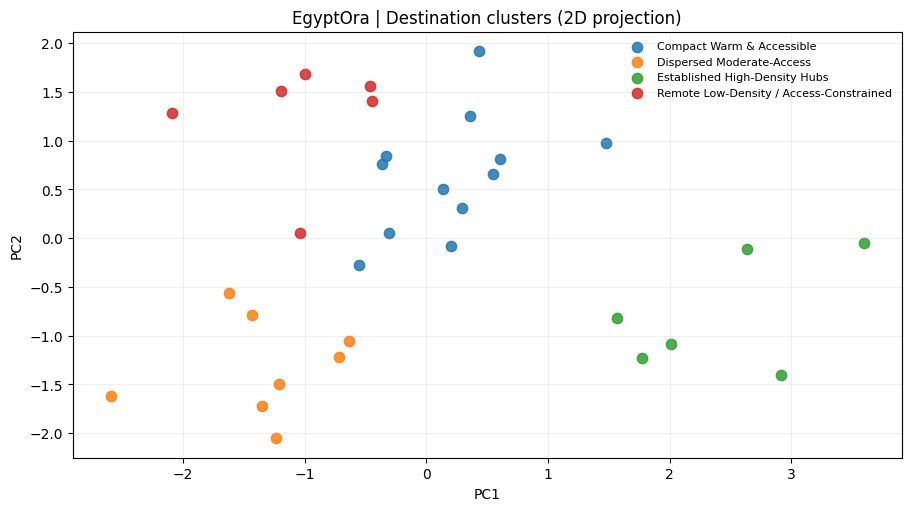

In [6]:
raw_labels = models[SELECTED_K].labels_
reference_ids = source.set_index("destination_id").loc[df.destination_id, "cluster_id"].astype(int).to_numpy()
ari = adjusted_rand_score(reference_ids, raw_labels)
print(f"Membership agreement (Adjusted Rand Index): {ari:.6f}")
if not np.isclose(ari, 1.0):
    raise ValueError("Membership differs from published capstone; review business labels before continuing.")
contingency = pd.crosstab(pd.Series(raw_labels, name="fitted"), pd.Series(reference_ids, name="published"))
r, c = linear_sum_assignment(-contingency.to_numpy())
label_map = dict(zip(contingency.index[r], contingency.columns[c]))
df["cluster_id"] = pd.Series(raw_labels).map(label_map).astype(int)
lookup = reference_profiles.set_index("cluster_id")
for target, original in [("cluster_name", "cluster_name"), ("cluster_description", "description"), ("cluster_recommendation", "recommendation")]:
    df[target] = df.cluster_id.map(lookup[original])
df["pca1"], df["pca2"] = X_pca[:, 0], X_pca[:, 1]
profiles = df.groupby(["cluster_id", "cluster_name"]).agg(destinations=("destination_id", "size"), **{f: (f, "mean") for f in features}).reset_index()
profiles["recommendation"] = profiles.cluster_id.map(lookup.recommendation)
display(profiles.round(2))
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for name, group in df.groupby("cluster_name"):
    ax.scatter(group.pca1, group.pca2, label=name, s=55, alpha=.85)
ax.set(xlabel="PC1", ylabel="PC2", title="EgyptOra | Destination clusters (2D projection)")
ax.grid(alpha=.2); ax.legend(fontsize=8, loc="best", frameon=False)
plt.show()

## 6. Similar destination engine
Compute Euclidean distances in the **standardized original feature space**, not in the PCA projection. Exclude self-matches and rank the three nearest destinations. Reproduce the capstone's similarity index: `100 × (1 − distance / maximum pairwise distance)`. This is a relative index for this dataset, not a probability, model accuracy, or personalized travel recommendation.

In [7]:
distances = pairwise_distances(X_scaled, metric="euclidean")
max_distance = distances.max()
assert max_distance > 0
rows = []
for i, query in df.iterrows():
    nearest = sorted((j for j in range(len(df)) if j != i), key=lambda j: (distances[i, j], df.loc[j, "destination_id"]))[:3]
    for rank, j in enumerate(nearest, 1):
        other = df.loc[j]
        rows.append({"query_destination": query.destination, "rank": rank,
                     "similar_destination": other.destination, "standardized_distance": distances[i, j],
                     "similarity_index_pct": 100 * (1 - distances[i, j] / max_distance),
                     "same_cluster": "Yes" if query.cluster_id == other.cluster_id else "No",
                     "query_cluster_id": query.cluster_id, "query_cluster_name": query.cluster_name,
                     "similar_cluster_id": other.cluster_id, "similar_cluster_name": other.cluster_name})
similar = pd.DataFrame(rows)
assert similar.groupby("query_destination").size().eq(3).all()
assert similar.query_destination.ne(similar.similar_destination).all()
assert similar.similarity_index_pct.between(0, 100).all()
print(f"Generated {len(similar)} recommendations for {len(df)} destinations")
display(similar.loc[similar.query_destination.isin(["Cairo", "El Gouna"])].round(2))

Generated 96 recommendations for 32 destinations


,query_destination,rank,similar_destination,standardized_distance,similarity_index_pct,same_cluster,query_cluster_id,query_cluster_name,similar_cluster_id,similar_cluster_name
0,Cairo,1,Giza,1.03,85.03,Yes,1,Established High-Density Hubs,1,Established High-Density Hubs
1,Cairo,2,Alexandria,1.39,79.75,Yes,1,Established High-Density Hubs,1,Established High-Density Hubs
2,Cairo,3,Luxor East Bank,1.61,76.48,Yes,1,Established High-Density Hubs,1,Established High-Density Hubs
57,El Gouna,1,Hurghada,0.96,86.05,Yes,2,Compact Warm & Accessible,2,Compact Warm & Accessible
58,El Gouna,2,Abydos and Sohag,1.07,84.43,Yes,2,Compact Warm & Accessible,2,Compact Warm & Accessible
59,El Gouna,3,Aswan,1.08,84.28,Yes,2,Compact Warm & Accessible,2,Compact Warm & Accessible


## 7. Reconcile with capstone reference outputs
Compare independently calculated metrics, cluster memberships, counts and nearest-neighbor outputs with the supplied workbook. Agreement is a reproducibility check, **not** independent model validation.

In [8]:
comparison = evaluation.merge(reference_eval, on="K", suffixes=("_run", "_reference"))
metric_cols = ["Silhouette_Score", "Davies_Bouldin"]
for metric in metric_cols:
    comparison[f"{metric}_delta"] = comparison[f"{metric}_run"] - comparison[f"{metric}_reference"]
display(comparison[["K"] + [f"{m}_delta" for m in metric_cols]].round(8))
joined = similar.merge(reference_similar, on=["query_destination", "rank"], suffixes=("_run", "_ref"), validate="one_to_one")
checks = {
    "38 total / 32 eligible / 6 excluded": (len(source), len(df), len(excluded)) == (38, 32, 6),
    "PCA retains at least 90% variance": pca.explained_variance_ratio_.sum() >= .90,
    "Candidate metrics reproduce workbook": all(np.allclose(comparison[f"{m}_delta"], 0, atol=1e-6) for m in metric_cols),
    "Candidate cluster sizes match": comparison.Cluster_Sizes_run.eq(comparison.Cluster_Sizes_reference).all(),
    "Selected cluster memberships match": np.isclose(ari, 1.0),
    "Selected cluster counts match": sorted(df.cluster_id.value_counts()) == sorted(reference_profiles.destinations),
    "96 similarity ranks and destinations match": len(joined) == len(similar) == len(reference_similar) == 96 and joined.similar_destination_run.eq(joined.similar_destination_ref).all(),
    "Similarity distances and indices match": all(np.allclose(joined[f"{m}_run"], joined[f"{m}_ref"], atol=1e-6) for m in ["standardized_distance", "similarity_index_pct"]),
    "Similarity business IDs match": all(joined[f"{m}_run"].eq(joined[f"{m}_ref"]).all() for m in ["same_cluster", "query_cluster_id", "similar_cluster_id"]),
}
audit = pd.DataFrame({"Check": list(checks), "Status": ["PASS" if v else "REVIEW" for v in checks.values()]})
display(audit)
print(f"Passed {sum(checks.values())}/{len(checks)} reproducibility checks")
assert all(checks.values()), "Reference discrepancy; review the audit table before publishing regenerated outputs."

,K,Silhouette_Score_delta,Davies_Bouldin_delta
0,2,0.0,0.0
1,3,-0.0,0.0
2,4,-0.0,0.0
3,5,0.0,0.0
4,6,0.0,-0.0


,Check,Status
0,38 total / 32 eligible / 6 excluded,PASS
1,PCA retains at least 90% variance,PASS
2,Candidate metrics reproduce workbook,PASS
3,Candidate cluster sizes match,PASS
4,Selected cluster memberships match,PASS
5,Selected cluster counts match,PASS
6,96 similarity ranks and destinations match,PASS
7,Similarity distances and indices match,PASS
8,Similarity business IDs match,PASS


Passed 9/9 reproducibility checks


## 8. Optional exports and limitations
Set `EXPORT_CSV = True` in section 0 and rerun if you need standalone generated tables. Exports go to `ml-generated/` beside the source workbook. They do not overwrite the original Excel or Power BI model. The exclusions remain separately documented.

**Limitations:** 32 eligible destinations is a small descriptive sample; excluded destinations are not represented. A Silhouette score near 0.358 indicates imperfect separation, not 35.8% accuracy. Attraction inventory is not visitor demand, distances are not road travel times, and climate is modeled. Recommendations are exploratory and depend on chosen features and data coverage. No out-of-sample performance, forecast accuracy or causality is established.

**Credit:** This is a reproducibility-focused revision of a collaborative capstone; original workbook business labels and recommendations are preserved. Data sources and redistribution permissions remain governed by the original providers and team agreements.

In [9]:
if EXPORT_CSV:
    out = path.parent / "ml-generated"
    out.mkdir(exist_ok=True)
    for name, frame in {"destinations": df, "excluded": excluded, "cluster_profiles": profiles,
                        "model_evaluation": evaluation, "similar_destinations": similar, "reproducibility_checks": audit}.items():
        frame.to_csv(out / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"Exported tables to {out}")
else:
    print("CSV export disabled; original workbook unchanged.")

CSV export disabled; original workbook unchanged.
